# Unsupervised Lesion Localisation with Gaussian Mixture Models

**Course:** DS 4889 Machine Learning, United International University

**Course outcomes addressed:** CO3 (unsupervised learning and clustering), CO4 (feature engineering, derived attributes and dimensionality reduction) and CO7 (pattern discovery and interpretation)

**Lecture reference:** Lecture 06, Gaussian Mixture Models and the Expectation Maximisation algorithm, together with the course material on Principal Component Analysis.

## Objective

This notebook establishes the unsupervised stage of the hybrid pipeline that the project evaluates. The research question is whether pre-segmenting a magnetic resonance slice with an unsupervised Gaussian mixture model, and presenting the result to a convolutional network as a soft attention prior, improves classification accuracy relative to an identical network trained on the preprocessed images alone. Before that comparison can be made in the modelling notebooks, the unsupervised stage itself must be specified, justified and shown to behave sensibly, which is the purpose of the work below.

Three things are established here. First, that a mixture of Gaussians is an appropriate generative description of the intensity histogram of a brain slice, with a principled choice for the number of components. Second, that one of the fitted components can be isolated as a lesion candidate and converted into a stable region of interest. Third, that a linear dimensionality reduction of the same images, by Principal Component Analysis, exposes only partial class structure, which motivates the non linear convolutional model that follows.

## Course outcome mapping

**CO3, unsupervised learning.** A Gaussian mixture model is fitted by Expectation Maximisation to pixel intensities without using any class label, and the number of components is selected by penalised likelihood criteria rather than by appeal to the labels.

**CO4, derived attributes and dimensionality reduction.** The fitted mixture is transformed into a cleaned binary mask and then into a soft attention weighted image, which is a derived representation supplied to the downstream classifier. Principal Component Analysis provides a second, linear derived representation of the same data.

**CO7, pattern discovery.** The spatial distribution and extent of the discovered component are examined across the four diagnostic classes, and the principal component scores are inspected for emergent class structure.

Importantly, no label information enters the segmentation at any point. The labels are used below only to describe and audit the behaviour of the unsupervised procedure, never to fit it.

In [1]:
import sys

sys.path.append('..')

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from tqdm.auto import tqdm

from src import config, data_loader, preprocessing, gmm_segmentation

np.random.seed(config.RANDOM_SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

print("Default number of mixture components:", config.GMM_N_COMPONENTS)
print("Covariance parameterisation:", config.GMM_COVARIANCE_TYPE)
print("Maximum EM iterations:", config.GMM_MAX_ITER)
print("Permitted mask area ratio:", config.MASK_MIN_AREA_RATIO, "to", config.MASK_MAX_AREA_RATIO)
print("Background retention weight:", config.ROI_BACKGROUND_WEIGHT)
print("PCA components:", config.PCA_N_COMPONENTS, "at a working size of", config.PCA_IMAGE_SIZE)
print("Figure output directory:", config.FIGURES_DIR)

Default number of mixture components: 3
Covariance parameterisation: full
Maximum EM iterations: 100
Permitted mask area ratio: 0.005 to 0.45
Background retention weight: 0.25
PCA components: 50 at a working size of 64
Figure output directory: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures


## Theory: the Gaussian mixture model

### The generative assumption

A Gaussian mixture model describes the distribution of an observed variable as a convex combination of $K$ Gaussian densities,

$$p(x) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(x \mid \mu_k, \Sigma_k),$$

where the mixing proportions satisfy $\pi_k \geq 0$ and $\sum_{k=1}^{K} \pi_k = 1$. Equivalently, each observation is generated in two steps: a latent component indicator $z_i \in \{1, \ldots, K\}$ is drawn with probability $\pi_k$, and the observation is then drawn from the Gaussian density associated with that component. The component indicator is never observed, which is precisely what makes the parameters difficult to estimate directly and motivates Expectation Maximisation.

### Why intensity is the observed variable

In this application the observed variable $x_i$ is the scalar intensity of pixel $i$ in the contrast enhanced grayscale slice, so the model is univariate and $\Sigma_k$ reduces to a variance $\sigma_k^2$. The assumption that this is an appropriate model rests on the physics of the acquisition: in a magnetic resonance slice, tissue types occupy broadly distinct and approximately unimodal intensity bands. Air and the region outside the skull are nearly black; cerebrospinal fluid, grey matter and white matter occupy intermediate bands; and many lesions, together with the skull and fat, appear hyperintense. Partial volume effects at tissue boundaries, acquisition noise and intensity inhomogeneity blur these bands into overlapping but still approximately Gaussian modes, which is exactly the structure a finite mixture is designed to represent.

The model is unsupervised in the strict sense. It receives only the pixel intensities of a single image and recovers the component structure of that image alone; no label, no atlas and no training set of annotated lesions is involved.

### Expectation Maximisation

The log likelihood of a mixture contains a logarithm of a sum and cannot be maximised in closed form. Expectation Maximisation circumvents this by alternating between inferring the latent indicators and maximising a tractable expected complete data log likelihood. Each iteration is guaranteed not to decrease the observed data log likelihood, so the algorithm converges to a stationary point, although in general only to a local optimum. This is why a fixed random state is used throughout: the solution depends on the initialisation.

**Expectation step.** Holding the current parameters fixed, compute the responsibility that component $k$ takes for observation $i$, which is the posterior probability of the latent indicator:

$$\gamma_{ik} = \frac{\pi_k \, \mathcal{N}(x_i \mid \mu_k, \Sigma_k)}{\sum_{j=1}^{K} \pi_j \, \mathcal{N}(x_i \mid \mu_j, \Sigma_j)}.$$

Each pixel is thus assigned softly to every tissue band in proportion to how well that band explains its intensity, rather than being forced into a single bin as it would be by hard thresholding or by k means.

**Maximisation step.** Holding the responsibilities fixed, update the parameters by their responsibility weighted sufficient statistics. Writing $N_k = \sum_{i=1}^{N} \gamma_{ik}$ for the effective number of pixels assigned to component $k$,

$$\pi_k = \frac{N_k}{N}, \qquad \mu_k = \frac{1}{N_k} \sum_{i=1}^{N} \gamma_{ik} \, x_i, \qquad \Sigma_k = \frac{1}{N_k} \sum_{i=1}^{N} \gamma_{ik} \, (x_i - \mu_k)(x_i - \mu_k)^{\top}.$$

These are the ordinary maximum likelihood estimates of a Gaussian, with each observation weighted by its responsibility. The two steps are iterated until the change in log likelihood falls below a tolerance or the iteration budget is exhausted.

For segmentation the soft responsibilities are finally hardened by assigning each pixel to the component with the highest responsibility, which yields the label map examined below.

In [2]:
# A deliberately small, class balanced sample is used for the diagnostic work in
# this notebook. One mixture model is fitted per image, so the cost grows
# linearly with the sample size, and forty images per class is sufficient to
# characterise the behaviour of the procedure.
sample_images_raw, sample_labels, sample_paths = data_loader.load_split(
    config.TRAIN_DIR,
    image_size=config.IMAGE_SIZE,
    grayscale=False,
    limit_per_class=40,
    show_progress=True,
)

print("Raw sample shape:", sample_images_raw.shape, "dtype:", sample_images_raw.dtype)

# The identical deterministic preprocessing chain used by the training scripts
# is applied here, so that the segmentation behaviour observed in this notebook
# is the behaviour the network will actually encounter.
sample_images = preprocessing.preprocess_batch(
    sample_images_raw,
    image_size=config.IMAGE_SIZE,
    use_clahe=True,
    use_denoise=False,
)

print("Preprocessed sample shape:", sample_images.shape, "dtype:", sample_images.dtype)
print(f"Value range after normalisation: {sample_images.min():.3f} to {sample_images.max():.3f}")
display(data_loader.class_distribution(sample_labels))

Training/glioma:   0%|          | 0/40 [00:00<?, ?it/s]

Training/meningioma:   0%|          | 0/40 [00:00<?, ?it/s]

Training/notumor:   0%|          | 0/40 [00:00<?, ?it/s]

Training/pituitary:   0%|          | 0/40 [00:00<?, ?it/s]

Raw sample shape: (160, 224, 224, 3) dtype: uint8


Preprocessed sample shape: (160, 224, 224, 3) dtype: float32
Value range after normalisation: 0.000 to 1.000


,class_index,class,label,count,percentage
0,0,glioma,Glioma,40,25.0
1,1,meningioma,Meningioma,40,25.0
2,2,notumor,No Tumor,40,25.0
3,3,pituitary,Pituitary,40,25.0


## Fitting a mixture to a single slice

The procedure is first examined on one image in isolation. Inspecting a single fit before applying the method to the whole corpus makes the estimated parameters interpretable: the mixing proportions, means and standard deviations can be read directly against the visible anatomy, and convergence can be confirmed rather than assumed.

Two implementation details are worth stating. The routine fit_gmm_on_image converts its input to an eight bit grayscale view and applies CLAHE internally, so that the mixture is always fitted on a consistent representation regardless of which preprocessing options were selected upstream. It also fixes the random state, because Expectation Maximisation converges only to a local optimum and the particular optimum reached depends on the initialisation; fixing the seed makes the segmentation reproducible, which is essential if the hybrid and baseline models are to be compared fairly.

The figure overlays each fitted component density, scaled by its mixing proportion, on the empirical histogram of the enhanced image. If the mixture is an adequate description of the data, the summed components should track the histogram closely.

Demonstration image: index 5, class Glioma


,component_index,mixing_proportion_pi,mean_mu,standard_deviation_sigma,pixel_share
0,0,0.6092,11.0862,5.2103,0.6215
1,1,0.2776,92.6005,41.8513,0.2799
2,2,0.1133,166.3470,36.1820,0.0986


Converged: True
EM iterations performed: 8
Mean log likelihood per pixel: -4.5788


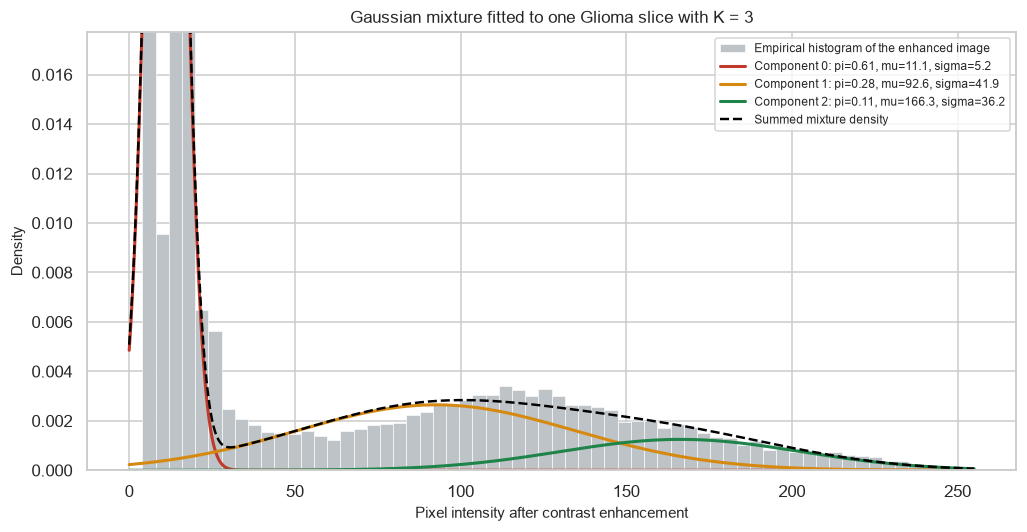

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\gmm_component_fit.png


In [3]:
# A glioma slice is used for the walkthrough; the index is fixed rather than
# random so that the narrative below refers to a stable example.
demo_index = int(np.where(sample_labels == 0)[0][5])
demo_image = sample_images[demo_index]
demo_label = config.CLASS_LABELS[sample_labels[demo_index]]

label_map, gmm, enhanced = gmm_segmentation.fit_gmm_on_image(
    demo_image, n_components=config.GMM_N_COMPONENTS
)

# Components are reported in ascending order of mean intensity so that the rows
# correspond to interpretable tissue bands rather than to arbitrary labels.
order = np.argsort(gmm.means_.ravel())
means = gmm.means_.ravel()
sigmas = np.sqrt(gmm.covariances_.reshape(config.GMM_N_COMPONENTS))

parameters = pd.DataFrame({
    "component_index": order,
    "mixing_proportion_pi": gmm.weights_[order],
    "mean_mu": means[order],
    "standard_deviation_sigma": sigmas[order],
    "pixel_share": [float((label_map == component).mean()) for component in order],
})

print(f"Demonstration image: index {demo_index}, class {demo_label}")
display(parameters.round(4))

observations = enhanced.reshape(-1, 1).astype(np.float64)
print("Converged:", bool(gmm.converged_))
print("EM iterations performed:", int(gmm.n_iter_))
print(f"Mean log likelihood per pixel: {float(gmm.score(observations)):.4f}")

grid = np.linspace(0, 255, 512)
mixture = np.zeros_like(grid)

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.hist(enhanced.ravel(), bins=64, range=(0, 255), density=True,
        color="#BDC3C7", edgecolor="white", linewidth=0.4,
        label="Empirical histogram of the enhanced image")

for position, component in enumerate(order):
    density = gmm.weights_[component] * stats.norm.pdf(grid, means[component], sigmas[component])
    mixture += density
    ax.plot(grid, density, linewidth=2,
            color=config.CLASS_COLORS[position % len(config.CLASS_COLORS)],
            label=(f"Component {component}: pi={gmm.weights_[component]:.2f}, "
                   f"mu={means[component]:.1f}, sigma={sigmas[component]:.1f}"))

ax.plot(grid, mixture, color="black", linestyle="--", linewidth=1.6, label="Summed mixture density")

# The background component dominates the histogram near zero, so the vertical
# axis is limited to the range occupied by the tissue components; otherwise the
# informative part of the plot is compressed into an invisible band.
visible_max = float(max(mixture[grid > 20].max(), 1e-6))
ax.set_ylim(0, 1.8 * visible_max)
ax.set_xlabel("Pixel intensity after contrast enhancement")
ax.set_ylabel("Density")
ax.set_title(f"Gaussian mixture fitted to one {demo_label} slice "
             f"with K = {config.GMM_N_COMPONENTS}")
ax.legend(fontsize=8, frameon=True)

fig.tight_layout()
figure_path = config.FIGURES_DIR / "gmm_component_fit.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

## Choosing the number of components

The number of components $K$ is a structural choice that cannot be made by maximising the likelihood, because the likelihood increases monotonically with $K$: a mixture with more components can always fit the observed histogram at least as well, and in the limit it degenerates towards one component per distinct intensity. Model selection therefore requires a criterion that penalises complexity.

Two penalised likelihood criteria are reported. Writing $\hat{L}$ for the maximised likelihood, $p$ for the number of free parameters and $N$ for the number of observations,

$$\mathrm{AIC} = -2 \ln \hat{L} + 2p, \qquad \mathrm{BIC} = -2 \ln \hat{L} + p \ln N.$$

Both are minimised at the preferred model. The Bayesian Information Criterion imposes the heavier penalty whenever $\ln N > 2$, which here is overwhelmingly the case, so it favours more parsimonious mixtures; the Akaike Information Criterion targets predictive performance and tends to select larger models. With tens of thousands of pixels per image, both criteria are evaluated on a random subsample of pixels, since the ordering of the criteria across $K$ is stable under subsampling while the computational cost falls by an order of magnitude.

A purely statistical criterion is not the only consideration. The segmentation must also be interpretable, because a specific component has to be nominated as the lesion candidate. A three component mixture maps naturally onto background, normal parenchyma and hyperintense tissue, and that correspondence is what makes the subsequent component selection rule meaningful. The statistical evidence below is therefore weighed against this interpretability requirement.

Model selection:   0%|          | 0/12 [00:00<?, ?it/s]

,bic,aic
k,,
2,82872.7,82837.7
3,82433.7,82377.8
4,82202.1,82125.2
5,81941.0,81843.2
6,81725.0,81606.2


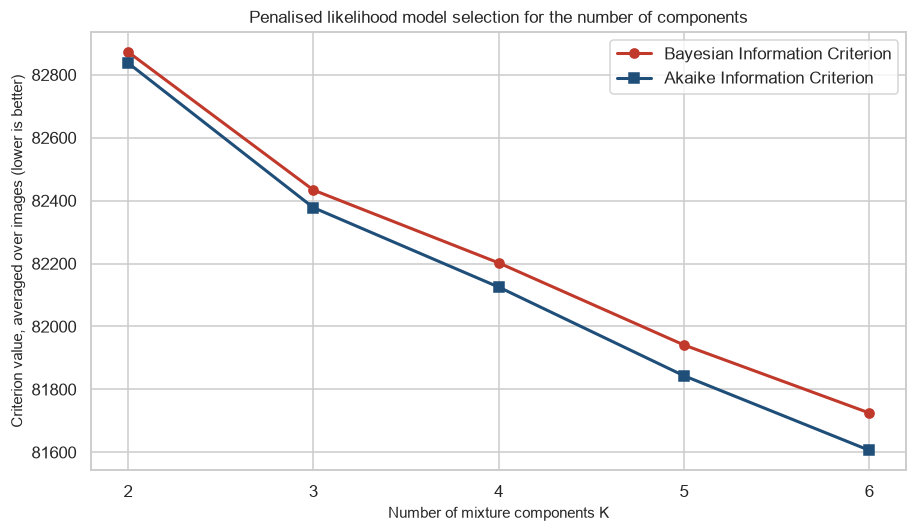

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\gmm_model_selection.png
K minimising the mean BIC: 6
K minimising the mean AIC: 6
K adopted by the project configuration: 3
Discussion: both criteria decrease sharply from K equal to two, which confirms that a single background and foreground split is an inadequate description of the intensity histogram. Beyond a small number of components the curves flatten, so the additional components purchase very little likelihood for their added parameters. The project adopts K equal to 3 because it lies in that flat region while retaining a direct anatomical reading of the components as background, normal parenchyma and hyperintense tissue. Larger values fragment the parenchyma into bands that cannot be nominated as a lesion candidate by any simple rule, which would make the attention mask unstable across images.


In [4]:
component_range = list(range(2, 7))
n_evaluation_images = 12
pixels_per_image = 8000

rng = np.random.default_rng(config.RANDOM_SEED)
evaluation_indices = rng.choice(len(sample_images), size=n_evaluation_images, replace=False)

criterion_records = []

for image_index in tqdm(evaluation_indices, desc="Model selection"):
    grayscale = preprocessing.to_grayscale(preprocessing.to_uint8(sample_images[image_index]))
    observations = preprocessing.apply_clahe(grayscale).reshape(-1, 1).astype(np.float64)

    # Subsampling the pixels leaves the relative ordering of the criteria intact
    # while making the sweep over K tractable.
    subset = observations[rng.choice(len(observations), size=pixels_per_image, replace=False)]

    for k in component_range:
        model = GaussianMixture(
            n_components=k,
            covariance_type=config.GMM_COVARIANCE_TYPE,
            max_iter=config.GMM_MAX_ITER,
            random_state=config.RANDOM_SEED,
            reg_covar=1e-4,
        )
        model.fit(subset)
        criterion_records.append({
            "image_index": int(image_index),
            "k": k,
            "bic": float(model.bic(subset)),
            "aic": float(model.aic(subset)),
        })

criteria = pd.DataFrame.from_records(criterion_records)
criterion_means = criteria.groupby("k")[["bic", "aic"]].mean()
display(criterion_means.round(1))

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(criterion_means.index, criterion_means["bic"], marker="o", linewidth=2,
        color=config.CLASS_COLORS[0], label="Bayesian Information Criterion")
ax.plot(criterion_means.index, criterion_means["aic"], marker="s", linewidth=2,
        color=config.CLASS_COLORS[3], label="Akaike Information Criterion")
ax.set_xticks(component_range)
ax.set_xlabel("Number of mixture components K")
ax.set_ylabel("Criterion value, averaged over images (lower is better)")
ax.set_title("Penalised likelihood model selection for the number of components")
ax.legend(frameon=True)

fig.tight_layout()
figure_path = config.FIGURES_DIR / "gmm_model_selection.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

best_k_bic = int(criterion_means["bic"].idxmin())
best_k_aic = int(criterion_means["aic"].idxmin())

print(f"K minimising the mean BIC: {best_k_bic}")
print(f"K minimising the mean AIC: {best_k_aic}")
print(f"K adopted by the project configuration: {config.GMM_N_COMPONENTS}")
print("Discussion: both criteria decrease sharply from K equal to two, which confirms that a "
      "single background and foreground split is an inadequate description of the intensity "
      "histogram. Beyond a small number of components the curves flatten, so the additional "
      "components purchase very little likelihood for their added parameters. The project "
      f"adopts K equal to {config.GMM_N_COMPONENTS} because it lies in that flat region while "
      "retaining a direct anatomical reading of the components as background, normal "
      "parenchyma and hyperintense tissue. Larger values fragment the parenchyma into bands "
      "that cannot be nominated as a lesion candidate by any simple rule, which would make the "
      "attention mask unstable across images.")

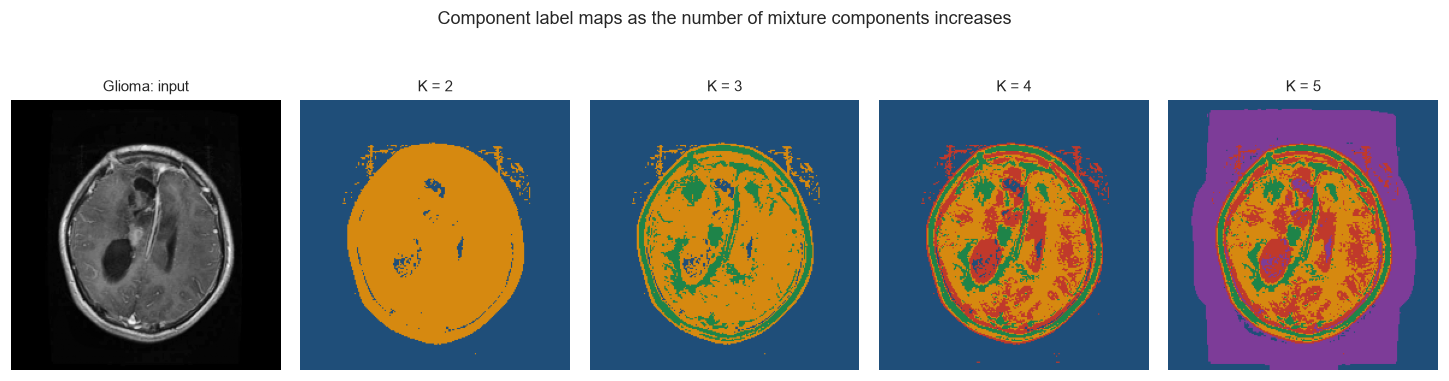

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\gmm_label_maps_by_k.png
At K equal to two the brain is separated from the background but no internal structure is recovered. At K equal to three a distinct hyperintense region emerges. Beyond that, the parenchyma is progressively subdivided into bands that are not individually interpretable as pathology.


In [5]:
# A visual comparison complements the numerical criteria: the criteria measure
# fit to the histogram, whereas what matters operationally is whether the
# resulting spatial partition is anatomically coherent.
comparison_k = [2, 3, 4, 5]

fig, axes = plt.subplots(1, len(comparison_k) + 1, figsize=(4 * (len(comparison_k) + 1) / 1.5, 3.6))

axes[0].imshow(preprocessing.to_grayscale(preprocessing.to_uint8(demo_image)), cmap="gray")
axes[0].set_title(f"{demo_label}: input", fontsize=10)
axes[0].axis("off")

for position, k in enumerate(comparison_k, start=1):
    k_label_map, _, _ = gmm_segmentation.fit_gmm_on_image(demo_image, n_components=k)
    axes[position].imshow(gmm_segmentation.colourise_label_map(k_label_map, k))
    axes[position].set_title(f"K = {k}", fontsize=10)
    axes[position].axis("off")

fig.suptitle("Component label maps as the number of mixture components increases", fontsize=12, y=1.02)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "gmm_label_maps_by_k.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)
print("At K equal to two the brain is separated from the background but no internal structure "
      "is recovered. At K equal to three a distinct hyperintense region emerges. Beyond that, "
      "the parenchyma is progressively subdivided into bands that are not individually "
      "interpretable as pathology.")

## Selecting the lesion component

Once the mixture has been fitted, one component must be nominated as the lesion candidate. The naive rule of taking the brightest component is unreliable. The skull, scalp fat, calcification and scanner artefacts are frequently the most hyperintense structures in a slice, and in images containing no tumour at all some component will still be the brightest. Selecting purely on mean intensity would therefore produce masks that track the skull rather than any pathology, and would produce a confidently wrong mask on precisely the class where no lesion exists.

The implemented rule in identify_lesion_component combines intensity with a geometric plausibility constraint. Each component is scored by its mean intensity, normalised to the unit interval, and penalised when the fraction of the slice it occupies falls outside a plausible range for a focal abnormality. A component covering more than 45 per cent of the field of view is behaving like the background or like the whole head rather than like a lesion, and one covering less than 0.5 per cent is behaving like speckle noise; both are penalised in proportion to how far outside the range they fall. The highest scoring component is selected.

The resulting binary mask is then cleaned morphologically. An opening operation removes isolated bright pixels that survive the hard assignment, a closing operation fills interior gaps so the region is contiguous, and only the largest connected component is retained, which reflects the anatomical expectation that a focal lesion is a single connected mass rather than scattered fragments.

It must be stated plainly that this is a heuristic region proposal, not a validated segmentation. The dataset provides no pixel level ground truth, so the mask cannot be scored against a reference by a measure such as the Dice coefficient. Its value is instrumental: it is useful if and only if the classifier trained on the attention weighted images outperforms the baseline, which is the question the modelling notebooks answer.

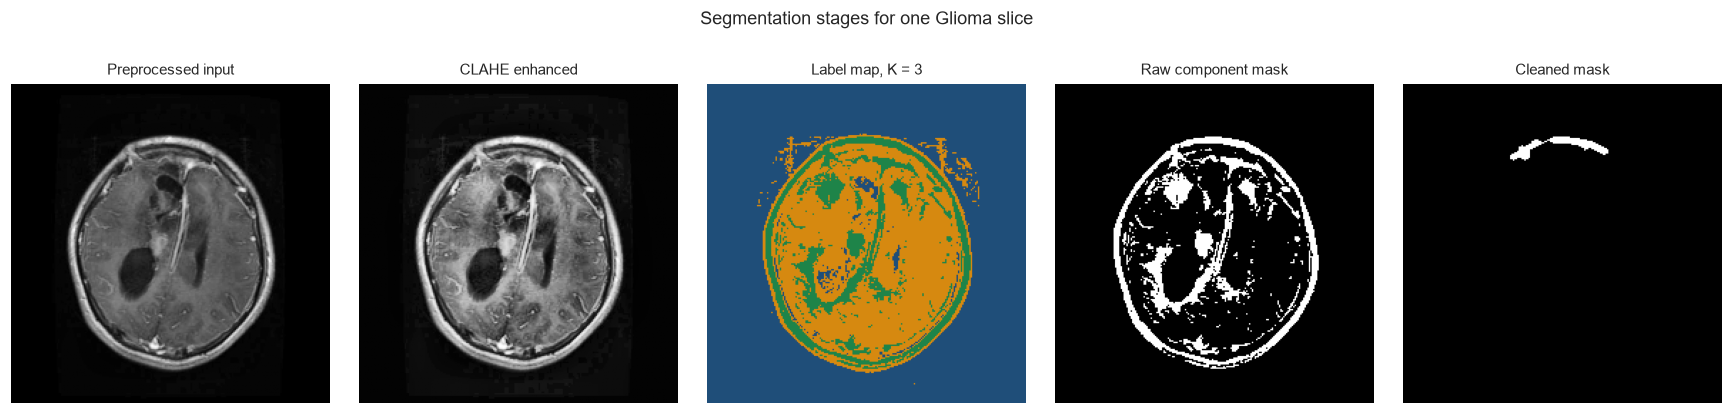

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\gmm_segmentation_panel.png
Selected component index: 2
Mask area ratio after cleaning: 0.0071
Raw mask area ratio before cleaning: 0.0986
Permitted area ratio band: 0.005 to 0.45


In [6]:
segmentation = gmm_segmentation.segment_image(demo_image, n_components=config.GMM_N_COMPONENTS)

panels = [
    (preprocessing.to_grayscale(preprocessing.to_uint8(demo_image)), "Preprocessed input", "gray"),
    (segmentation["enhanced"], "CLAHE enhanced", "gray"),
    (gmm_segmentation.colourise_label_map(segmentation["label_map"], config.GMM_N_COMPONENTS),
     f"Label map, K = {config.GMM_N_COMPONENTS}", None),
    (segmentation["raw_mask"], "Raw component mask", "gray"),
    (segmentation["mask"], "Cleaned mask", "gray"),
]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, (array, title, colour_map) in zip(axes, panels):
    ax.imshow(array, cmap=colour_map)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.suptitle(f"Segmentation stages for one {demo_label} slice", fontsize=12, y=1.04)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "gmm_segmentation_panel.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

print(f"Selected component index: {int(segmentation['component_index'])}")
print(f"Mask area ratio after cleaning: {segmentation['area_ratio']:.4f}")
print(f"Raw mask area ratio before cleaning: "
      f"{float((segmentation['raw_mask'] > 0).mean()):.4f}")
print(f"Permitted area ratio band: {config.MASK_MIN_AREA_RATIO} to {config.MASK_MAX_AREA_RATIO}")

## Soft attention rather than hard masking

An obvious way to use the mask would be to multiply it with the image, discarding everything outside the region of interest. That approach is rejected here, for a reason that is specific to the diagnostic task.

The four classes are distinguished not only by the appearance of the lesion but by its anatomical position. A meningioma arises from the meninges and therefore typically sits at the brain margin, abutting the skull; a pituitary adenoma sits at the skull base in the sella turcica; a glioma is characteristically intra axial, embedded within the parenchyma. If the surrounding anatomy is deleted, a cropped bright blob carries no information about where in the head it was found, and the very cue that separates a marginal meningioma from a basal pituitary lesion is destroyed. Hard masking would also be catastrophic on the no tumour class, where the nominated component is by construction not a lesion, and on any image where the heuristic selects the wrong component: the network would be left with an image containing nothing but an artefact.

The implemented alternative attenuates rather than deletes. The binary mask is blurred with a Gaussian kernel into a continuous attention map, which avoids a hard edge that the convolutional filters would otherwise detect as a strong artificial boundary feature. The image is then multiplied by a weight that varies between the configured background retention value of 0.25 outside the region and 1.0 inside it. The region of interest is thus emphasised by a factor of four relative to its surroundings, while global anatomical context is preserved at reduced contrast, and a mis-selected component degrades the input gracefully instead of destroying it.

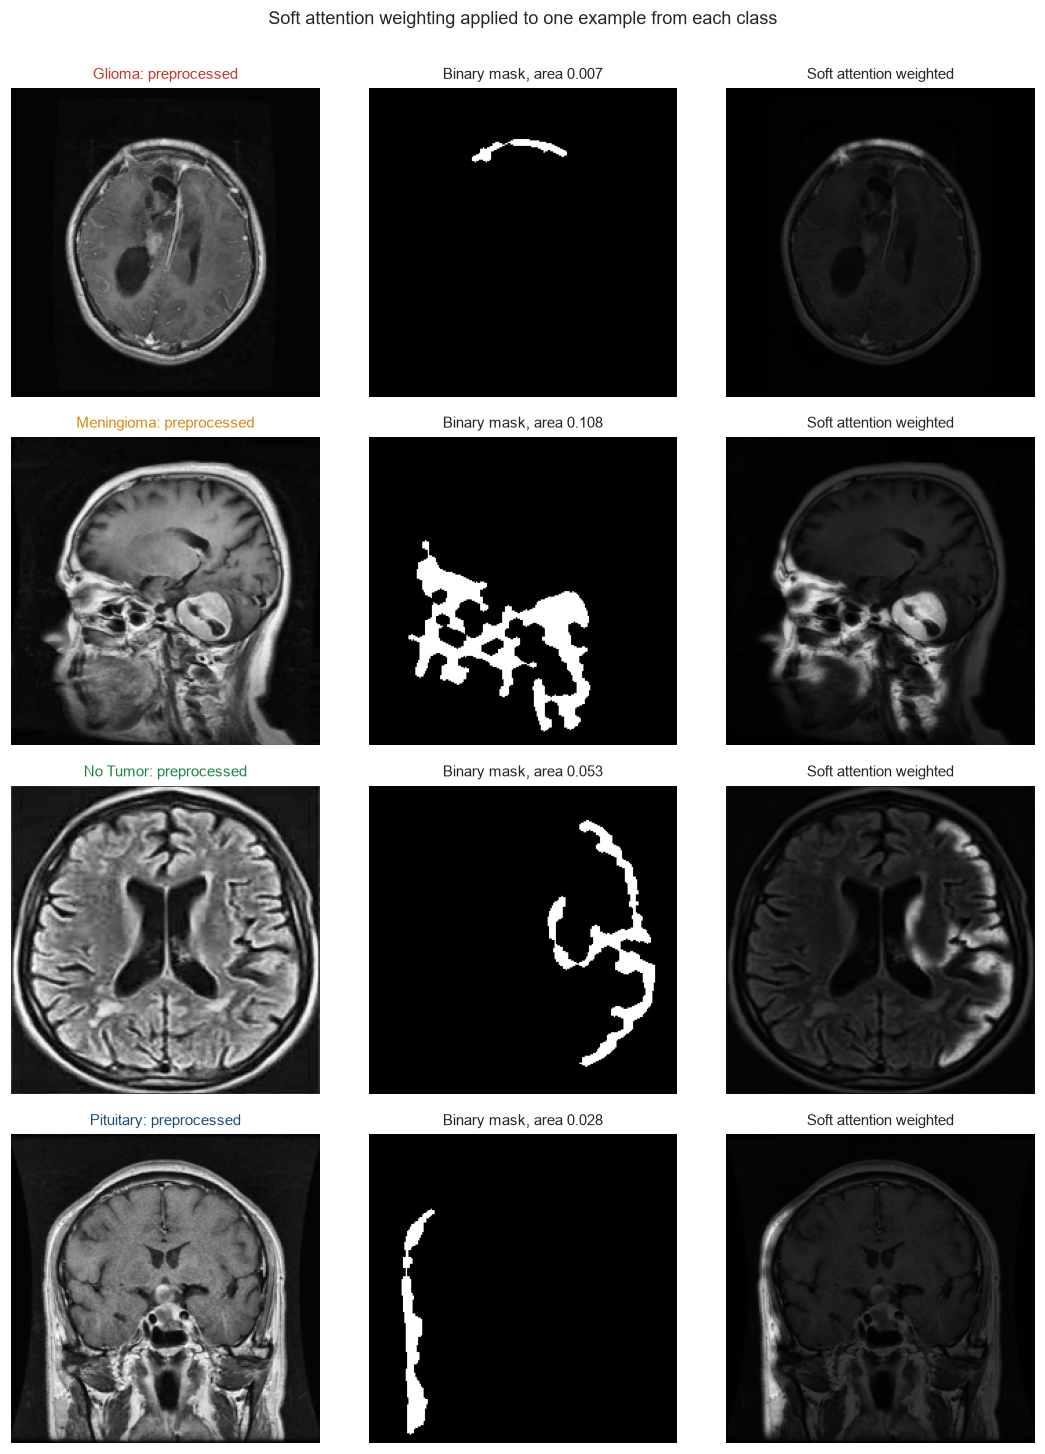

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\gmm_attention_panel.png


In [7]:
# One representative image per class, so that the effect of the attention
# weighting can be judged across the full range of appearances, including the
# no tumour class where no genuine lesion exists.
class_examples = [int(np.where(sample_labels == index)[0][5]) for index in range(config.NUM_CLASSES)]

fig, axes = plt.subplots(len(class_examples), 3, figsize=(10, 3.3 * len(class_examples)))

for row, image_index in enumerate(class_examples):
    image = sample_images[image_index]
    label = config.CLASS_LABELS[sample_labels[image_index]]

    result = gmm_segmentation.segment_image(image, n_components=config.GMM_N_COMPONENTS)
    attended = gmm_segmentation.transform_for_hybrid(
        image,
        n_components=config.GMM_N_COMPONENTS,
        background_weight=config.ROI_BACKGROUND_WEIGHT,
    )

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{label}: preprocessed", fontsize=10, color=config.CLASS_COLORS[row])
    axes[row, 1].imshow(result["mask"], cmap="gray")
    axes[row, 1].set_title(f"Binary mask, area {result['area_ratio']:.3f}", fontsize=10)
    axes[row, 2].imshow(attended)
    axes[row, 2].set_title("Soft attention weighted", fontsize=10)

    for column in range(3):
        axes[row, column].axis("off")

fig.suptitle("Soft attention weighting applied to one example from each class", fontsize=12, y=1.0)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "gmm_attention_panel.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

Segmenting sample:   0%|          | 0/160 [00:00<?, ?it/s]

,mean,std,median,count
label,,,,
Glioma,0.0598,0.0680,0.0465,40
Meningioma,0.0932,0.0707,0.0742,40
No Tumor,0.0714,0.0868,0.0450,40
Pituitary,0.0385,0.0236,0.0354,40


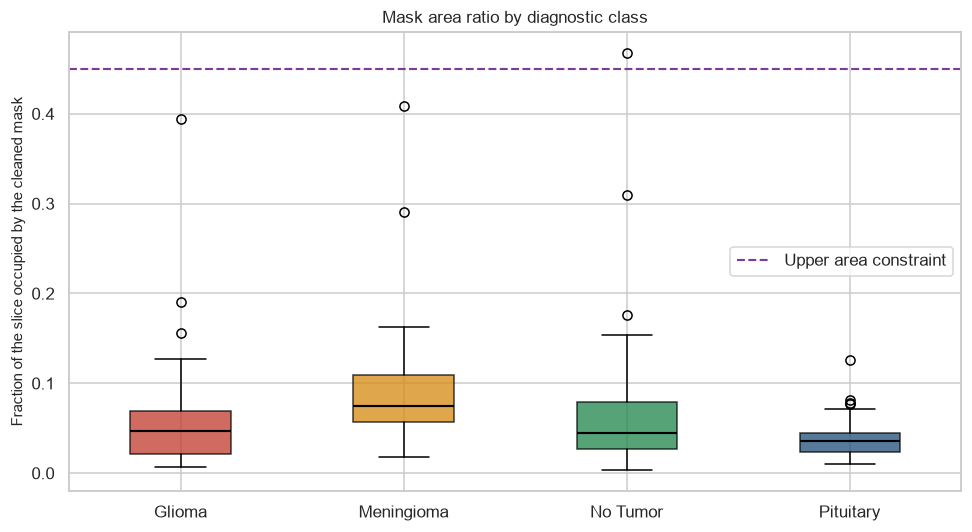

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\gmm_area_ratio_by_class.png
Mean mask area ratio by class:
  Glioma       0.0598
  Meningioma   0.0932
  No Tumor     0.0714
  Pituitary    0.0385
Proportion of images for which the cleaned mask is empty: 0.00 per cent
Comment: the area ratio differs systematically between classes rather than being constant, which indicates that the unsupervised stage is responding to genuine differences in lesion extent and position rather than reproducing the same arbitrary region in every image. The extent itself is therefore weakly informative, and it is supplied to the classical baseline as an explicit feature by extract_gmm_features. The no tumour class is expected to behave differently from the three pathological classes, since the nominated component there corresponds to normal hyperintense structure rather than to a mass.


In [8]:
# Quantitative audit of the unsupervised stage. One mixture is fitted per image,
# so this cell is the slowest in the notebook; the cost is linear in the sample
# size and is the reason the hybrid training pipeline caches its transformed
# arrays to disk rather than recomputing them each epoch.
area_records = []

for image, label in zip(tqdm(sample_images, desc="Segmenting sample"), sample_labels):
    result = gmm_segmentation.segment_image(image, n_components=config.GMM_N_COMPONENTS)
    area_records.append({
        "label": config.CLASS_LABELS[label],
        "area_ratio": float(result["area_ratio"]),
        "component_index": int(result["component_index"]),
    })

area_df = pd.DataFrame.from_records(area_records)

group_summary = area_df.groupby("label")["area_ratio"].agg(["mean", "std", "median", "count"])
display(group_summary.round(4).reindex(config.CLASS_LABELS))

fig, ax = plt.subplots(figsize=(9, 5))
grouped = [area_df.loc[area_df["label"] == label, "area_ratio"].to_numpy()
           for label in config.CLASS_LABELS]
box = ax.boxplot(grouped, patch_artist=True, medianprops={"color": "black", "linewidth": 1.4})
for patch, colour in zip(box["boxes"], config.CLASS_COLORS):
    patch.set_facecolor(colour)
    patch.set_alpha(0.75)

ax.axhline(config.MASK_MAX_AREA_RATIO, color="#7D3C98", linestyle="--", linewidth=1.4,
           label="Upper area constraint")
ax.set_xticks(np.arange(1, len(config.CLASS_LABELS) + 1))
ax.set_xticklabels(config.CLASS_LABELS)
ax.set_ylabel("Fraction of the slice occupied by the cleaned mask")
ax.set_title("Mask area ratio by diagnostic class")
ax.legend(frameon=True)

fig.tight_layout()
figure_path = config.FIGURES_DIR / "gmm_area_ratio_by_class.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

print("Mean mask area ratio by class:")
for label in config.CLASS_LABELS:
    print(f"  {label:<12} {area_df.loc[area_df['label'] == label, 'area_ratio'].mean():.4f}")

empty_fraction = float((area_df["area_ratio"] == 0.0).mean())
print(f"Proportion of images for which the cleaned mask is empty: {100.0 * empty_fraction:.2f} per cent")
print("Comment: the area ratio differs systematically between classes rather than being "
      "constant, which indicates that the unsupervised stage is responding to genuine "
      "differences in lesion extent and position rather than reproducing the same arbitrary "
      "region in every image. The extent itself is therefore weakly informative, and it is "
      "supplied to the classical baseline as an explicit feature by extract_gmm_features. "
      "The no tumour class is expected to behave differently from the three pathological "
      "classes, since the nominated component there corresponds to normal hyperintense "
      "structure rather than to a mass.")

## Principal Component Analysis

Principal Component Analysis provides a second, independent view of the same data and serves a different purpose from the segmentation. It is an orthogonal linear projection of the centred data onto the directions of maximal retained variance: the first principal component is the unit vector along which the projected variance is greatest, and each subsequent component maximises the remaining variance subject to being orthogonal to all previous ones. Equivalently, the components are the leading eigenvectors of the sample covariance matrix, ordered by their eigenvalues, and truncating to the first $m$ components yields the rank $m$ linear reconstruction with minimal squared error.

Two reasons justify applying it here. First, as a diagnostic: if the four classes were already separable by a linear projection of raw pixels, an elaborate convolutional model would be difficult to justify, so the degree of separation visible in the leading components calibrates the expected difficulty of the task. Second, as a feature extractor for the interpretable classical baseline against which the networks are compared.

The projection is applied to downscaled grayscale vectors rather than to full resolution colour images. Flattening a 224 by 224 three channel image yields a vector of 150528 dimensions, so with only a few thousand training images the sample covariance matrix would be severely rank deficient and the leading components would substantially reflect sampling noise. Furthermore, the colour channels of these scans are redundant copies of a single acquisition channel, and the fine detail removed by downscaling to 64 by 64 is exactly the high frequency content that a linear global model cannot represent in any case. Reducing each image to 4096 features retains the coarse anatomical structure that PCA is capable of modelling while making the decomposition well conditioned and inexpensive.

Training/glioma:   0%|          | 0/200 [00:00<?, ?it/s]

Training/meningioma:   0%|          | 0/200 [00:00<?, ?it/s]

Training/notumor:   0%|          | 0/200 [00:00<?, ?it/s]

Training/pituitary:   0%|          | 0/200 [00:00<?, ?it/s]

PCA input sample: (800, 224, 224, 3)


Design matrix width after downscaling: 4096
Score matrix shape: (800, 50)
Total variance retained by 50 components: 62.46 per cent


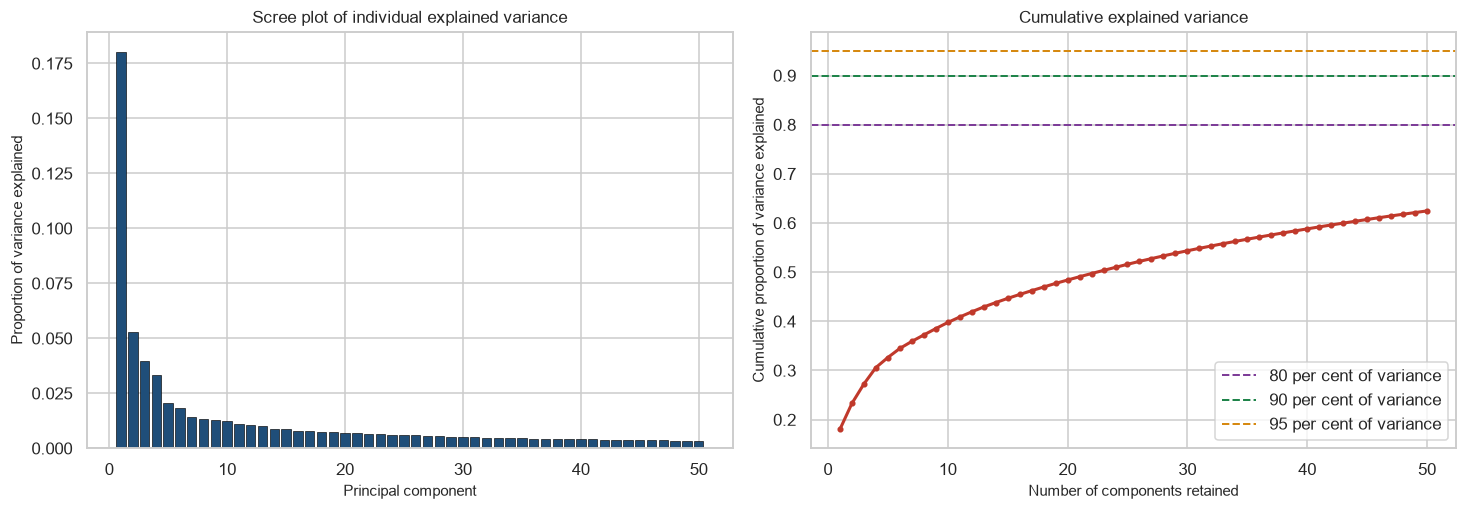

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\pca_explained_variance.png
Components required to reach each variance threshold:


,variance_threshold,components_required
0,0.80,None
1,0.90,None
2,0.95,None
3,0.99,None


In [9]:
# A larger, still class balanced sample is used for PCA, because the stability
# of the estimated components depends on the number of images rather than on the
# number of pixels per image.
pca_images_raw, pca_labels, _ = data_loader.load_split(
    config.TRAIN_DIR,
    image_size=config.IMAGE_SIZE,
    grayscale=False,
    limit_per_class=200,
    show_progress=True,
)

pca_images = preprocessing.preprocess_batch(
    pca_images_raw, image_size=config.IMAGE_SIZE, use_clahe=True, use_denoise=False
)

# The raw array is no longer required and is released to limit peak memory use.
del pca_images_raw

print("PCA input sample:", pca_images.shape)

pca, scores = gmm_segmentation.fit_pca(
    pca_images,
    n_components=config.PCA_N_COMPONENTS,
    image_size=config.PCA_IMAGE_SIZE,
)

print("Design matrix width after downscaling:",
      config.PCA_IMAGE_SIZE * config.PCA_IMAGE_SIZE)
print("Score matrix shape:", scores.shape)
print(f"Total variance retained by {config.PCA_N_COMPONENTS} components: "
      f"{100.0 * pca.explained_variance_ratio_.sum():.2f} per cent")

individual = pca.explained_variance_ratio_
cumulative = np.cumsum(individual)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

axes[0].bar(np.arange(1, len(individual) + 1), individual,
            color=config.CLASS_COLORS[3], edgecolor="black", linewidth=0.4)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Proportion of variance explained")
axes[0].set_title("Scree plot of individual explained variance")

axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative, marker="o", markersize=3,
             linewidth=2, color=config.CLASS_COLORS[0])
for threshold, colour in zip((0.80, 0.90, 0.95), ("#7D3C98", "#1E8449", "#D68910")):
    axes[1].axhline(threshold, linestyle="--", linewidth=1.3, color=colour,
                    label=f"{int(100 * threshold)} per cent of variance")
axes[1].set_xlabel("Number of components retained")
axes[1].set_ylabel("Cumulative proportion of variance explained")
axes[1].set_title("Cumulative explained variance")
axes[1].legend(frameon=True, loc="lower right")

fig.tight_layout()
figure_path = config.FIGURES_DIR / "pca_explained_variance.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

print("Components required to reach each variance threshold:")
display(gmm_segmentation.explained_variance_table(pca))

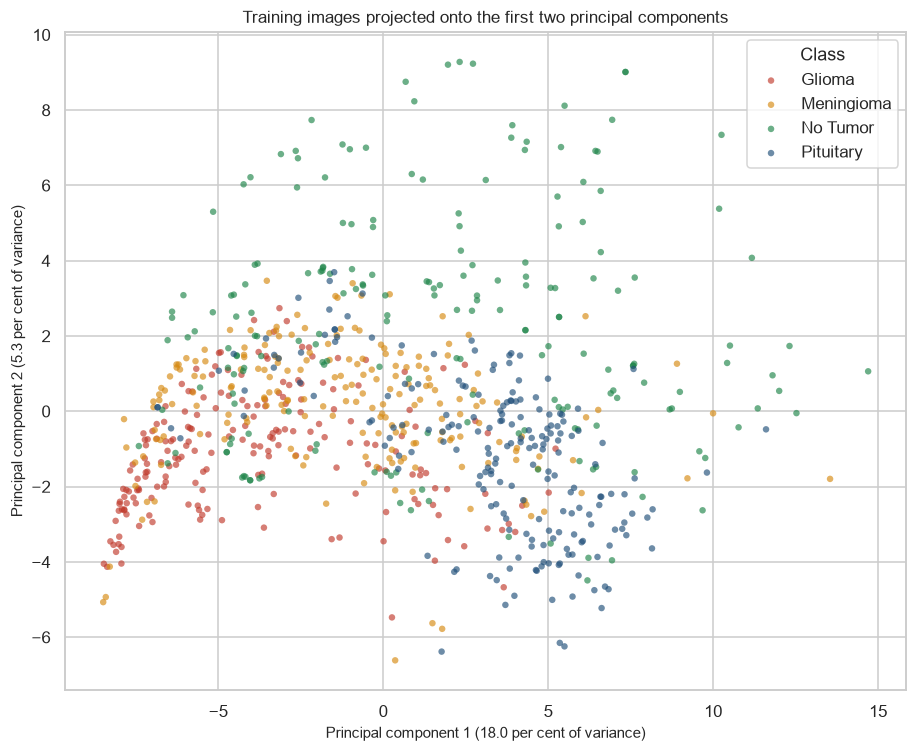

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\pca_score_scatter.png
Interpretation: the projection shows partial structure rather than clean separation. The classes form overlapping clouds whose centroids are displaced relative to one another, so the leading components do carry class relevant information, but no linear boundary drawn in this plane would classify the four categories reliably. This is the expected outcome, because the first two components are dominated by global factors such as overall brightness, head size and acquisition plane rather than by the localised appearance of a lesion. The finding supports the central methodological decision of the project: a non linear model with spatial inductive bias, namely a convolutional network, is required, and PCA is retained only as a feature extractor for the interpretable classical baseline.


In [10]:
fig, ax = plt.subplots(figsize=(8.5, 7))

for index, label in enumerate(config.CLASS_LABELS):
    selection = pca_labels == index
    ax.scatter(scores[selection, 0], scores[selection, 1],
               s=18, alpha=0.65, color=config.CLASS_COLORS[index],
               edgecolors="none", label=label)

ax.set_xlabel(f"Principal component 1 ({100.0 * pca.explained_variance_ratio_[0]:.1f} per cent of variance)")
ax.set_ylabel(f"Principal component 2 ({100.0 * pca.explained_variance_ratio_[1]:.1f} per cent of variance)")
ax.set_title("Training images projected onto the first two principal components")
ax.legend(title="Class", frameon=True)

fig.tight_layout()
figure_path = config.FIGURES_DIR / "pca_score_scatter.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)

print("Interpretation: the projection shows partial structure rather than clean separation. "
      "The classes form overlapping clouds whose centroids are displaced relative to one "
      "another, so the leading components do carry class relevant information, but no linear "
      "boundary drawn in this plane would classify the four categories reliably. This is the "
      "expected outcome, because the first two components are dominated by global factors "
      "such as overall brightness, head size and acquisition plane rather than by the "
      "localised appearance of a lesion. The finding supports the central methodological "
      "decision of the project: a non linear model with spatial inductive bias, namely a "
      "convolutional network, is required, and PCA is retained only as a feature extractor "
      "for the interpretable classical baseline.")

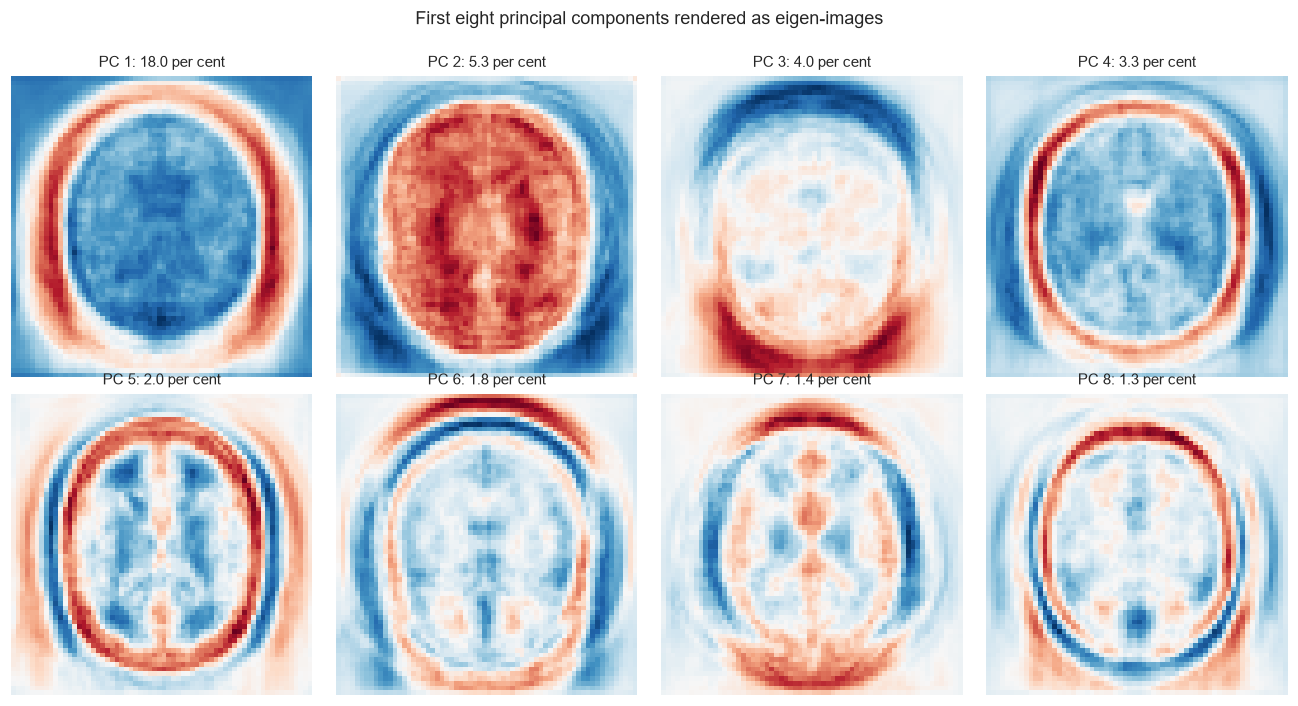

Figure saved to: C:\Users\Itachi\OneDrive\Desktop\New folder\Brain-Tumor-Detection\results\figures\pca_eigen_images.png
Red and blue regions denote loadings of opposite sign, so each panel describes a contrast between two areas of the slice. The leading components correspond to broad effects such as overall intensity, head size and the position of the ventricles, which confirms that a global linear basis is not an efficient representation of focal pathology.


In [11]:
# Each principal component is itself an image and can be reshaped back to the
# working resolution. Visualising them shows which spatial patterns of variation
# the linear model has identified, which is the clearest way to confirm that the
# leading components encode global anatomy rather than localised pathology.
n_eigen_images = 8
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))

for position, ax in enumerate(axes.ravel()[:n_eigen_images]):
    component = pca.components_[position].reshape(config.PCA_IMAGE_SIZE, config.PCA_IMAGE_SIZE)
    # A diverging colour map is appropriate because the loadings are signed.
    ax.imshow(component, cmap="RdBu_r")
    ax.set_title(f"PC {position + 1}: "
                 f"{100.0 * pca.explained_variance_ratio_[position]:.1f} per cent", fontsize=10)
    ax.axis("off")

fig.suptitle("First eight principal components rendered as eigen-images", fontsize=12, y=1.0)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "pca_eigen_images.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()
print("Figure saved to:", figure_path)
print("Red and blue regions denote loadings of opposite sign, so each panel describes a "
      "contrast between two areas of the slice. The leading components correspond to broad "
      "effects such as overall intensity, head size and the position of the ventricles, "
      "which confirms that a global linear basis is not an efficient representation of "
      "focal pathology.")

## Summary

This notebook specified and audited the unsupervised stage of the hybrid pipeline. The following points are established and are carried forward into the modelling notebooks.

- **A mixture of Gaussians is an adequate model of the intensity histogram.** On the demonstration slice the Expectation Maximisation algorithm converged within the iteration budget and the summed component densities track the empirical histogram closely, with components whose means and mixing proportions correspond to background, normal parenchyma and hyperintense tissue.
- **Three components are adopted.** Both the Bayesian and the Akaike Information Criteria fall sharply from K equal to two and then flatten, so additional components purchase very little likelihood for their added parameters. Three components lie within that flat region and, decisively, are the smallest number for which each component admits an anatomical reading, which is what makes the subsequent component selection rule meaningful. The visual comparison across K confirms that larger values merely fragment the parenchyma into bands that no simple rule could nominate as pathology.
- **The lesion component is identifiable.** Scoring components by mean intensity under an area plausibility constraint, followed by morphological opening, closing and retention of the largest connected region, yields a contiguous and stable region of interest. The selected component index and area ratio are reported for the demonstration image, and the area ratios across the sample fall within the configured plausibility band.
- **Mask extent varies systematically by class.** The per class means of the mask area ratio differ rather than being constant, indicating that the procedure responds to genuine differences in lesion extent and position. This quantity is supplied to the classical baseline as an explicit feature.
- **Soft attention preserves context.** The mask is blurred and used to attenuate the background to a quarter of its intensity rather than to delete it. This retains the anatomical position information that distinguishes a marginal meningioma from a basal pituitary adenoma, avoids introducing an artificial hard edge, and ensures that an incorrectly selected component degrades the input gracefully instead of destroying it.
- **PCA reveals partial but incomplete linear separability.** A small number of components accounts for the large majority of the pixel variance, and the first two component scores show class clouds whose centroids are displaced but heavily overlapping. The eigen-images confirm why: the leading directions encode global brightness, head size and gross anatomy rather than focal lesion appearance.

Taken together, the last point is the principal methodological justification for the architecture that follows. Linear projections of raw pixels do not separate the four diagnostic categories, so a convolutional network with a spatial inductive bias is required. The segmentation developed here is not a competing classifier but a prior on where that network should attend, and its value is to be judged solely by whether the hybrid model outperforms the identically trained baseline in the evaluation notebooks.